# 04 · Ước lượng hiệu ứng voucher và ngưỡng căng cung θ̂

Notebook dùng dữ liệu mô phỏng (W0 = quy mô Hà Nội, tiền VND; `runs/s8/w0`), kết quả phương pháp (`runs/s9/w0`: đường tác dụng theo độ căng trước khối) và thí nghiệm chính sách (`runs/s10/w0`: bảng chính sách 18 dòng, quét θ 16 mức × 30 seed). Mọi phép tính nằm trong `analysis/` (có test); notebook chỉ đọc và vẽ. Lệnh sinh lại dữ liệu ở README, mục *Tái lập kết quả*.


In [1]:
import json

import numpy as np
import pandas as pd

from analysis import metrics, evaluation, tension, tension_curve, theta, uplift
from analysis.estimate import experiment_frame
from analysis.io import load_tables
from analysis.notebook import require_runs, setup
from analysis.plots import GRID, INK, INK_2, MUTED, save_figure, vn
from analysis.policy_table import summarize
from analysis.qini_vs_value import policy_runs
from sim.config import load_config

plt = setup()
(ALL_OFF, ALL_ON, ALL_OFF_W1, SB_ALL, SB_C7, LEGACY, POLICY_TABLE, SW_RING_DR, S9, BUDGET) = require_runs(
    "runs/s8/w0/all_off_5seeds_full", "runs/s8/w0/all_on_5seeds_full", "runs/s8/w1/all_off_5seeds_full",
    "runs/s8/w0/switchback_call_28d", "runs/s8/w0/switchback_c7_28d", "runs/s8/w0/legacy_28d",
    "runs/s10/w0/policy_table", "runs/s10/w0/sweep_ring1_dr", "runs/s9/w0", "runs/s8/w0/calibrate_budget")
CFG = load_config("config/default.yaml")
CFG_W1 = load_config(["config/default.yaml", "config/world_w1.yaml"])
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"     # categorical slots 1-3 of the house palette (analysis/plots.py)


def tex(text: str) -> str:
    # Hats as matplotlib math text: the UI font misplaces the combining circumflex of θ̂ and τ̂.
    return text.replace("θ̂", r"$\hat{\theta}$").replace("τ̂", r"$\hat{\tau}$")


## 1. DR-learner: hiệu ứng voucher theo rider

Mỗi session có kết cục `Y` (1 nếu chuyến hoàn thành) và `T` (1 nếu được phát voucher). Hiệu ứng của một rider có đặc trưng `x` là
τ(x) = P(Y = 1 | phát, x) − P(Y = 1 | không phát, x). DR-learner (Kennedy 2023) học τ(x) qua *pseudo-outcome*

$$\varphi = \hat\mu_1 - \hat\mu_0 + \frac{T\,(Y-\hat\mu_1)}{\hat e} - \frac{(1-T)\,(Y-\hat\mu_0)}{1-\hat e},$$

với `μ̂₁, μ̂₀` là tỷ lệ hoàn thành dự báo khi có / không voucher và `ê` là xác suất được phát; rồi hồi quy φ theo `x`.
Các mô hình phụ học **chéo 5 phần theo rider** (mọi session của một rider cùng một phần), nên φ của một session không dùng mô hình đã thấy chính nó.

Hai mẫu: `dr_explore` chỉ dùng lát explore (phát ngẫu nhiên, `e = 0,5` đã biết) và `dr_all` dùng toàn bộ dữ liệu legacy (nhiều hơn, nhưng bị nhiễu do biến ẩn `u_latent`).

In [2]:
rows = []
for name in ("dr_explore", "dr_all", "dr_explore_w1", "dr_all_w1"):
    meta, _ = uplift.load_model(name)
    rows.append({"mô hình": name, "số session": meta["n"], "được phát": meta["n_treated"],
                 "so thô": meta["ate_naive"], "DR": meta["ate_dr"], "SE (DR)": meta["ate_dr_se"],
                 "chi / lượt phát (đ)": meta["mean_paid_per_offer_vnd"],
                 "% ê bị cắt về [0,02; 0,98]": 100 * meta["share_e_clipped"]})
pd.DataFrame(rows).set_index("mô hình").round(4)


,số session,được phát,so thô,DR,SE (DR),chi / lượt phát (đ),"% ê bị cắt về [0,02; 0,98]"
mô hình,,,,,,,
dr_explore,205624,100704,0.0556,0.0584,0.0015,3010.0641,0.0000
dr_all,4145947,933304,0.0877,0.0930,0.0003,3412.7998,34.7715
dr_explore_w1,210125,104155,0.0580,0.0593,0.0015,2989.1625,0.0000
dr_all_w1,4217860,944484,0.0903,0.0907,0.0003,3412.8722,35.5535


Hiệu ứng trung bình lên tỷ lệ hoàn thành (W0; W1 trùng trong sai số):
- **Lát explore:** DR ≈ so thô ≈ 0,058, đúng như kỳ vọng vì voucher được phát ngẫu nhiên (mốc không gây nhiễu).
- **Toàn bộ legacy:** DR ≈ so thô ≈ 0,093, **cao hơn lát explore 0,035**. Luật phát cũ nhắm theo `u_latent` (biến ẩn), nên DR-learner với đặc trưng quan sát được không gỡ được nhiễu — notebook 05 tách phần này.
- Chi mỗi lượt phát ≈ 3.000–3.400đ (voucher 25% giá, trần 20.000đ, chỉ trả khi chuyến hoàn thành).


WindowsPath('C:/Work/VinAI/GSM/Supply-Aware-Promotion-Uplift/docs/figures/04_tau_x_theo_rider.png')

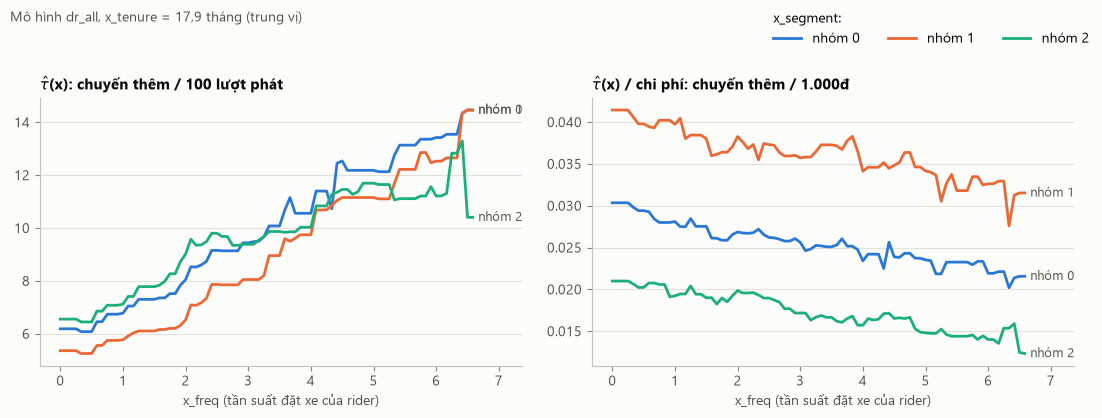

In [3]:
riders = load_tables(LEGACY, ["observed/riders"])["riders"]
grid = np.linspace(0.0, float(riders["x_freq"].quantile(0.99)), 80)
tenure = float(riders["x_tenure"].median())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for seg, color in zip(range(3), (C1, C2, C3)):
    feats = {"x_freq": grid, "x_tenure": np.full_like(grid, tenure), "x_segment": np.full_like(grid, seg),
             "slack_lag_slot": np.zeros_like(grid)}
    pred = uplift.predict_scores("dr_all", feats)
    for ax, key, scale in ((axes[0], "tau_x", 100.0), (axes[1], "tau_x_per_kvnd", 1.0)):
        y = scale * pred[key]
        ax.plot(grid, y, color=color, linewidth=2, label=f"nhóm {seg}")
        ax.annotate(f"nhóm {seg}", xy=(grid[-1], y[-1]), xytext=(4, 0), textcoords="offset points",
                    va="center", color=INK_2, fontsize=9)
axes[0].set_title(tex("τ̂(x): chuyến thêm / 100 lượt phát"))
axes[1].set_title(tex("τ̂(x) / chi phí: chuyến thêm / 1.000đ"))
for ax in axes:
    ax.set_xlabel("x_freq (tần suất đặt xe của rider)")
    ax.set_xlim(right=grid[-1] * 1.12)                       # room for the direct labels
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, frameon=False, loc="upper right", ncol=3, title="x_segment:", alignment="left")
fig.suptitle(f"Mô hình dr_all, x_tenure = {vn(tenure, 1)} tháng (trung vị)", x=0.01, ha="left", color=INK_2, fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.93))
save_figure(fig, "04_tau_x_theo_rider")

Hai cách xếp hạng rider ngược nhau:
- **Theo lượt phát** (trái): rider đặt xe nhiều có hiệu ứng mỗi lượt phát cao.
- **Theo mỗi 1.000đ** (phải): rider đặt xe nhiều lại kém nhất, vì họ đi chuyến dài hơn nên voucher 25% giá (trần 20.000đ) tốn hơn và vì họ hoàn thành nhiều hơn nên voucher được trả nhiều hơn.

Dưới ngân sách, cách thứ hai mới là cách đúng (bảng dưới).


In [4]:
policy_runs_df = policy_runs(POLICY_TABLE)
B = float(policy_runs_df["budget_B_vnd"].max())
SCORES = {"random": "ngẫu nhiên", "heuristic": "heuristic (ưu tiên tần suất thấp)",
          "tau_x": "τ̂(x) nền (bảng)", "tau_per_vnd": "τ̂(x)/1.000đ nền (bảng)",
          "tau_x_dr_kvnd": "τ̂(x)/1.000đ DR, explore", "tau_xs_dr_kvnd": "τ̂(x, s)/1.000đ DR, explore",
          "tau_x_dr_all": "τ̂(x) DR, toàn bộ", "tau_xs_dr_all": "τ̂(x, s) DR, toàn bộ",
          "tau_x_dr_all_kvnd": "τ̂(x)/1.000đ DR, toàn bộ", "tau_xs_dr_all_kvnd": "τ̂(x, s)/1.000đ DR, toàn bộ",
          "oracle": "oracle (biết hệ số thật của từng rider)"}
by_score = summarize(policy_runs_df, reference="random", order=list(SCORES)).set_index("label")
by_score = by_score.assign(tên=pd.Series(SCORES)).sort_values("dN_vs_ref")
by_score[["tên", "N_mean", "N_se", "dN_vs_ref", "dN_vs_ref_se", "spent_mean"]].round(1)


,tên,N_mean,N_se,dN_vs_ref,dN_vs_ref_se,spent_mean
label,,,,,,
tau_x_dr_all,"τ̂(x) DR, toàn bộ",20518.6,18.2,-244.6,10.9,112892144.0
tau_x,τ̂(x) nền (bảng),20676.4,18.8,-86.8,9.4,113734332.5
tau_xs_dr_all,"τ̂(x, s) DR, toàn bộ",20742.7,19.2,-20.5,9.1,110758020.3
random,ngẫu nhiên,20763.2,16.9,0.0,0.0,113744138.4
heuristic,heuristic (ưu tiên tần suất thấp),20977.1,17.5,213.9,8.7,113462147.5
tau_xs_dr_kvnd,"τ̂(x, s)/1.000đ DR, explore",21325.9,16.9,562.7,9.1,113718559.7
tau_x_dr_kvnd,"τ̂(x)/1.000đ DR, explore",21447.1,17.8,683.9,12.7,113755737.1
tau_per_vnd,τ̂(x)/1.000đ nền (bảng),21529.1,17.8,765.9,11.8,113489424.0
tau_x_dr_all_kvnd,"τ̂(x)/1.000đ DR, toàn bộ",21546.3,18.1,783.1,11.9,113446441.1


WindowsPath('C:/Work/VinAI/GSM/Supply-Aware-Promotion-Uplift/docs/figures/04_n_duoi_b_theo_diem.png')

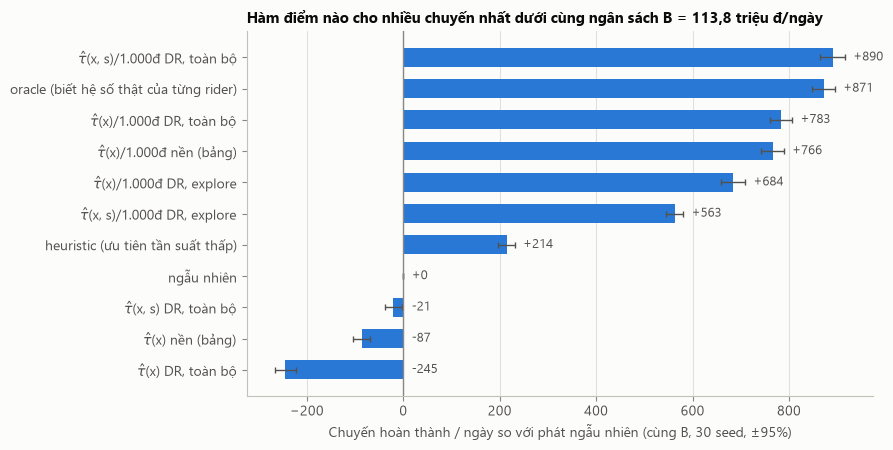

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(by_score))
d, se = by_score["dN_vs_ref"].to_numpy(), by_score["dN_vs_ref_se"].to_numpy()
ax.barh(y, d, xerr=1.96 * se, color=C1, height=0.6, error_kw={"ecolor": INK_2, "elinewidth": 1, "capsize": 2})
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(y, [tex(n) for n in by_score["tên"]])
for yi, v, s in zip(y, d, se):
    ax.annotate(f"{v:+.0f}", xy=(max(v + 1.96 * s, 0), yi), xytext=(6, 0), textcoords="offset points", va="center",
                color=INK_2, fontsize=9)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color=GRID)
ax.set_xlabel("Chuyến hoàn thành / ngày so với phát ngẫu nhiên (cùng B, 30 seed, ±95%)")
ax.set_title(f"Hàm điểm nào cho nhiều chuyến nhất dưới cùng ngân sách B = {vn(B / 1e6, 1)} triệu đ/ngày")
fig.tight_layout()
save_figure(fig, "04_n_duoi_b_theo_diem")

- Mọi điểm **theo mỗi 1.000đ** hơn phát ngẫu nhiên +680…+890 chuyến/ngày; mọi điểm **theo lượt phát** không hơn (DR theo lượt phát còn thua phát ngẫu nhiên −245 / −21). Bảng nền `τ̂(x)/1.000đ` (+766 so với ngẫu nhiên) gần bằng DR toàn bộ (+783): thứ tự xếp theo tiền quan trọng hơn mô hình.
- Học trên toàn bộ legacy (`_all`) tốt hơn chỉ lát explore (+783 so với +684): nhiều dữ liệu hơn thắng nhiễu ẩn, vì nhiễu chủ yếu làm sai *mức* τ̂ chứ ít làm sai *thứ tự* rider.
- Thêm `s` (slack dự báo của ô đón) vào hàm điểm: `τ̂(x, s)/1.000đ` toàn bộ **+1.298 so với all_on_B** là tầng rider tốt nhất, hơn oracle (+1.279) vì oracle chỉ biết hệ số của từng khách, không biết thị trường.


In [6]:
pair = summarize(policy_runs_df, reference="tau_x_dr_all_kvnd",
                 order=["tau_x_dr_all_kvnd", "tau_xs_dr_all_kvnd", "pi_tension_ring1_dr_kvnd", "pi_hourB_ring1_dr_kvnd",
                        "pi_hourB_city_dr_kvnd", "hour_off_dr_kvnd"]).set_index("label")
pair[["theta", "N_mean", "dN_vs_ref", "dN_vs_ref_se", "share_cells_off"]].round(1)


,theta,N_mean,dN_vs_ref,dN_vs_ref_se,share_cells_off
label,,,,,
tau_x_dr_all_kvnd,0.0,21546.3,0.0,0.0,0.0
tau_xs_dr_all_kvnd,0.0,21653.6,107.4,10.3,0.0
pi_tension_ring1_dr_kvnd,0.0,21546.3,0.0,0.0,0.0
pi_hourB_ring1_dr_kvnd,2.3,21706.8,160.5,12.7,0.5
pi_hourB_city_dr_kvnd,1.6,21825.3,279.1,12.8,0.4
hour_off_dr_kvnd,0.0,21802.9,256.6,10.2,0.0


So với tầng rider `τ̂(x)/1.000đ` (θ = 0): thêm `s` vào điểm +107 ± 13; tầng ô `ring1` ở θ̂_B = 2,3 **+160 ± 13**; tầng `city` ở θ̂_B = 1,6 **+279 ± 13**; luật tắt cố định ở giờ có hại **+257 ± 10**. Ngưỡng theo độ căng θ̂_tension = 0 (mục 4) trùng tầng rider. Phần thông tin căng cung mang lại là +160…+280 chuyến/ngày (0,7–1,3%); notebook 02 so các dòng này dưới cùng B trên cả W1.


## 2. Đo "căng cung" bằng chỉ số nào?

Tầng ô của chính sách tắt voucher khi chỉ số căng ŝ < θ. Quy tắc: chọn ŝ theo khả năng **dự báo mức phục vụ** (ETA báo cho khách, `no_supply`) trên dữ liệu `all_off` (không voucher, 5 seed × 1 ngày), đo ở slot trước. Bảy ứng viên: ba chỉ số theo ô, `ring1` (ô + 6 ô kề), cụm cố định 7 ô, toàn thành phố (`system` = `scope: city`), và giờ trong ngày (`hour`, mốc so sánh). Chấm trên cả W0 và W1.


In [7]:
frame = tension.run_frames(ALL_OFF, CFG)
share = float(np.mean(frame["cell_persistence"] < CFG.policy.threshold.theta))
indicators = tension.score_indicators(frame, n_bins=10, bad_eta_min=8.0, share=share).set_index("indicator")
frame_w1 = tension.run_frames(ALL_OFF_W1, CFG_W1)
share_w1 = float(np.mean(frame_w1["cell_persistence"] < CFG_W1.policy.threshold.theta))
indicators_w1 = tension.score_indicators(frame_w1, n_bins=10, bad_eta_min=8.0, share=share_w1).set_index("indicator")
print(f"W0: {len(frame):,} session, {frame['seed'].nunique()} seed × 1 ngày; gắn cờ {100 * share:.1f}% session. "
      f"W1: {len(frame_w1):,} session; gắn cờ {100 * share_w1:.1f}%")
pd.concat({"W0": indicators[["eta_r2", "bad_capture"]], "W1": indicators_w1[["eta_r2", "bad_capture"]]}, axis=1).round(3)


W0: 749,334 session, 5 seed × 1 ngày; gắn cờ 15.6% session. W1: 779,635 session; gắn cờ 22.6%


W0                 W1            
                 eta_r2 bad_capture eta_r2 bad_capture
indicator                                             
cell_persistence  0.131       0.300  0.182       0.438
cell_ar           0.132       0.300  0.182       0.438
cell_idle         0.194       0.340  0.231       0.470
ring1             0.187       0.308  0.254       0.478
cluster7          0.181       0.308  0.255       0.479
system            0.188       0.316  0.269       0.488
hour              0.213       0.308  0.248       0.394

WindowsPath('C:/Work/VinAI/GSM/Supply-Aware-Promotion-Uplift/docs/figures/04_chon_s_hat.png')

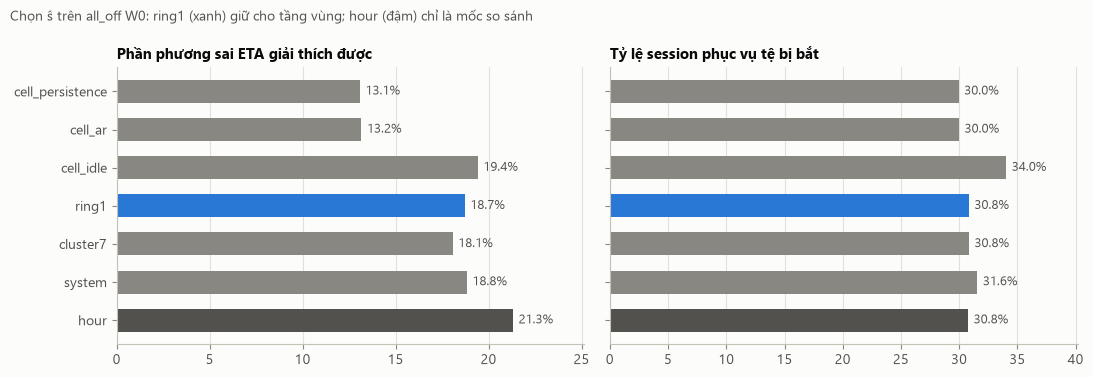

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
names = list(indicators.index)
colors = [C1 if n == "ring1" else (INK_2 if n == "hour" else MUTED) for n in names]
for ax, col, title in ((axes[0], "eta_r2", "Phần phương sai ETA giải thích được"),
                       (axes[1], "bad_capture", "Tỷ lệ session phục vụ tệ bị bắt")):
    v = 100 * indicators[col].to_numpy()
    ax.barh(np.arange(len(names)), v, color=colors, height=0.6)
    for i, x in enumerate(v):
        ax.annotate(f"{x:.1f}%", xy=(x, i), xytext=(4, 0), textcoords="offset points", va="center", color=INK_2, fontsize=9)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color=GRID)
    ax.set_xlim(0, 100 * indicators[col].max() * 1.18)
axes[0].set_yticks(np.arange(len(names)), names)
axes[0].invert_yaxis()
fig.suptitle("Chọn ŝ trên all_off W0: ring1 (xanh) giữ cho tầng vùng; hour (đậm) chỉ là mốc so sánh",
             x=0.01, ha="left", color=INK_2, fontsize=10)
fig.tight_layout()
save_figure(fig, "04_chon_s_hat")

- Trên **W0** (không biến động) giờ trong ngày dự báo ETA tốt ngang các chỉ số độ căng (R² 0,21 so với 0,19), vì căng còn lại chủ yếu theo giờ cao điểm.
- Trên **W1** (có mưa, sự kiện, cầu theo ngày) các chỉ số độ căng vượt `hour` rõ ở tỷ lệ bắt ca phục vụ tệ (0,48–0,49 so với 0,39): khi căng không chỉ theo giờ, chỉ số độ căng mới có giá trị. `system` nhỉnh nhất về dự báo nhưng bật/tắt cả thành phố; **`ring1`** ngang cụm 7 ô và giữ quyết định theo vùng, nên giữ cho tầng vùng; `city` được chạy như dòng so sánh ở bảng chính sách.
- Đo ở **một ô** (`cell_*`) dự báo kém nhất ở cả hai thế giới: một ô có ít xe, slack nhảy mạnh giữa các slot.


## 3. Voucher gây hại ở đâu, khi nào?

Voucher kéo thêm khách đặt xe. Lúc dư xe, khách thêm thành chuyến thêm. Lúc thiếu xe, khách thêm làm xe đi đón xa hơn, ETA tăng, nhiều khách hủy trong lúc chờ, và số chuyến hoàn thành có thể **giảm**. Phép so trực tiếp nhất: phát cho mọi khách so với không phát ai, cùng seed, không ngân sách, 5 seed (`runs/s8/w0/all_on_5seeds_full`, `all_off_5seeds_full`). Sau khi sửa lịch ca lúc hiệu chỉnh W0, tác hại 7–9h của thế giới cũ đổi chỗ: còn 8h và 17–19h.


In [9]:
on_off = theta.on_off_by_hour_runs(ALL_ON, ALL_OFF)
print(f"Cả ngày: phát cho mọi khách thêm {on_off['completed_diff'].sum():+.1f} chuyến so với không phát")
on_off.loc[[6, 7, 8, 9, 16, 17, 18, 19, 20]].round(2)


Cả ngày: phát cho mọi khách thêm +3828.6 chuyến so với không phát


,hour,completed_off,completed_diff,completed_diff_se,requests_diff,lost_diff,lost_rate_off,quoted_eta_off,quoted_eta_diff
6,6,699.4,234.0,9.78,294.2,60.2,0.05,3.94,1.30
7,7,1087.2,37.2,17.67,326.6,289.4,0.09,5.08,2.97
8,8,1108.6,-190.4,9.41,350.8,541.2,0.14,6.53,3.13
9,9,1062.8,106.0,8.35,340.0,234.0,0.07,4.58,2.59
16,16,1165.4,305.8,6.40,429.2,123.4,0.05,3.72,1.88
17,17,1276.2,-31.2,14.94,335.8,367.0,0.10,5.66,3.17
18,18,1088.4,-168.8,8.75,348.6,517.4,0.17,7.27,3.19
19,19,999.2,-85.2,16.06,302.6,387.8,0.12,6.39,3.15
20,20,944.8,19.8,14.68,267.0,247.2,0.08,4.98,2.85


WindowsPath('C:/Work/VinAI/GSM/Supply-Aware-Promotion-Uplift/docs/figures/04_tac_hai_bat_tat_toan_bo.png')

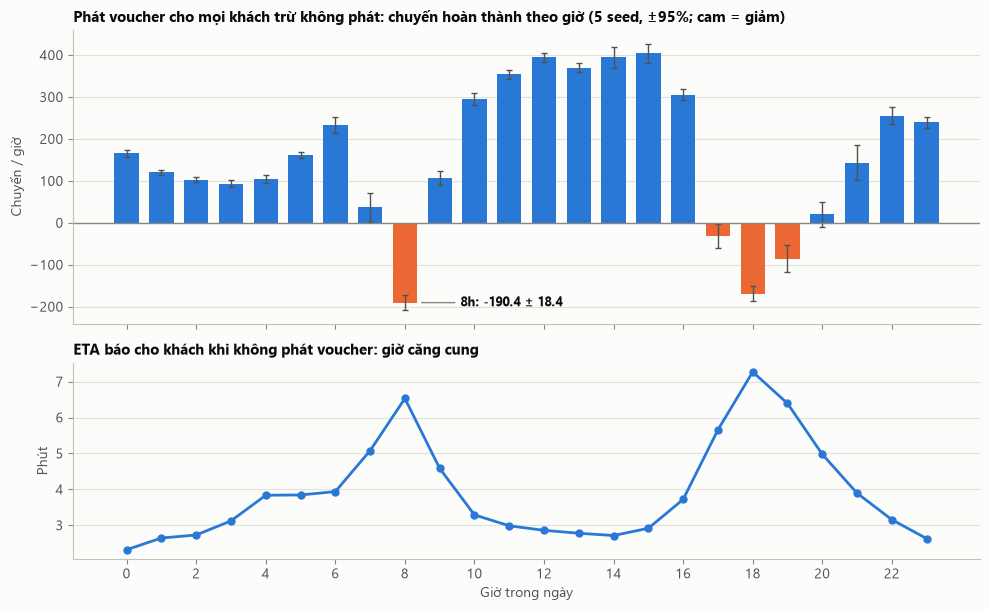

In [10]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True, height_ratios=[3, 2])
h = on_off["hour"].to_numpy()
d, se = on_off["completed_diff"].to_numpy(), on_off["completed_diff_se"].to_numpy()
ax1.bar(h, d, color=np.where(d < 0, C2, C1), width=0.7, yerr=1.96 * se,
        error_kw={"ecolor": INK_2, "elinewidth": 1, "capsize": 2})
ax1.axhline(0, color=MUTED, linewidth=1)
worst = int(np.argmin(d))
ax1.annotate(f"{h[worst]}h: {d[worst]:+.1f} ± {1.96 * se[worst]:.1f}", xy=(h[worst] + 0.4, d[worst]),
             xytext=(30, 0), textcoords="offset points", ha="left", va="center", color=INK, fontsize=9, fontweight="bold",
             arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 1})
ax1.set_ylabel("Chuyến / giờ")
ax1.set_title("Phát voucher cho mọi khách trừ không phát: chuyến hoàn thành theo giờ (5 seed, ±95%; cam = giảm)")
ax2.plot(h, on_off["quoted_eta_off"], color=C1, linewidth=2, marker="o", markersize=5)
ax2.set_ylabel("Phút")
ax2.set_title("ETA báo cho khách khi không phát voucher: giờ căng cung")
ax2.set_xlabel("Giờ trong ngày")
ax2.set_xticks(range(0, 24, 2))
fig.tight_layout()
save_figure(fig, "04_tac_hai_bat_tat_toan_bo")

Voucher **làm giảm** số chuyến hoàn thành lúc **8h** (−190 ± 9) và **17–19h** (−31, −169, −85), đúng các giờ ETA báo cao nhất (6,5 và 7,3 phút); cả ngày vẫn tăng nhiều. Vậy tắt voucher theo giờ và nơi căng cung là có cơ sở. Với lịch ca cũ (trước hiệu chỉnh W0) tác hại nằm ở 7–9h; dời xe sang sáng xóa 7h và 9h nhưng làm 17–19h hại hơn.

Một thí nghiệm thật không chạy được "mọi khách / không ai" cả ngày. Dữ liệu thí nghiệm có được là switchback: bật/tắt theo khối 60 phút. Hai câu hỏi: switchback có thấy đúng giờ gây hại không, và kiểu switchback nào thấy được.


In [11]:
frame_all = experiment_frame(SB_ALL)
eff_all = theta.hour_effects(frame_all, n_boot=300)
eff_c7 = theta.hour_effects(experiment_frame(SB_C7), n_boot=300)
by_hour = pd.concat({"toàn thành phố": theta.hour_table(eff_all), "cụm 7 ô": theta.hour_table(eff_c7)}, names=["thiết kế"])
harmful = tension_curve.harmful_hours(eff_all)
print("Giờ có hại theo switchback toàn thành phố (cận trên CI < 0):", harmful)
by_hour.loc[(slice(None), [6, 7, 8, 9, 16, 17, 18, 19, 20]), :].round(4)


Giờ có hại theo switchback toàn thành phố (cận trên CI < 0): [8, 17, 18, 19]


hour     tau      lo      hi       cost
thiết kế                                                  
toàn thành phố 6      6  0.0452  0.0414  0.0492  2990.4190
               7      7  0.0025  0.0002  0.0046  1929.9603
               8      8 -0.0155 -0.0173 -0.0137  1335.1035
               9      9  0.0170  0.0142  0.0195  2348.0144
               16    16  0.0311  0.0282  0.0345  2734.5923
               17    17 -0.0054 -0.0082 -0.0028  1699.7220
               18    18 -0.0117 -0.0137 -0.0101  1257.7429
               19    19 -0.0090 -0.0115 -0.0070  1535.8717
               20    20  0.0045  0.0012  0.0080  2098.3433
cụm 7 ô        6      6  0.0521  0.0479  0.0573  3050.7290
               7      7  0.0265  0.0236  0.0298  2206.9931
               8      8  0.0226  0.0198  0.0257  1699.0053
               9      9  0.0332  0.0303  0.0365  2571.3286
               16    16  0.0370  0.0329  0.0411  2801.3619
               17    17  0.0178  0.0147  0.0212  1942.3213
               18    18  0.0188  0.0153  0.0216  1525.9409
               19    19  0.0269  0.0236  0.0305  1916.6115
               20    20  0.0327  0.0284  0.0367  2423.9837

WindowsPath('C:/Work/VinAI/GSM/Supply-Aware-Promotion-Uplift/docs/figures/04_switchback_theo_gio.png')

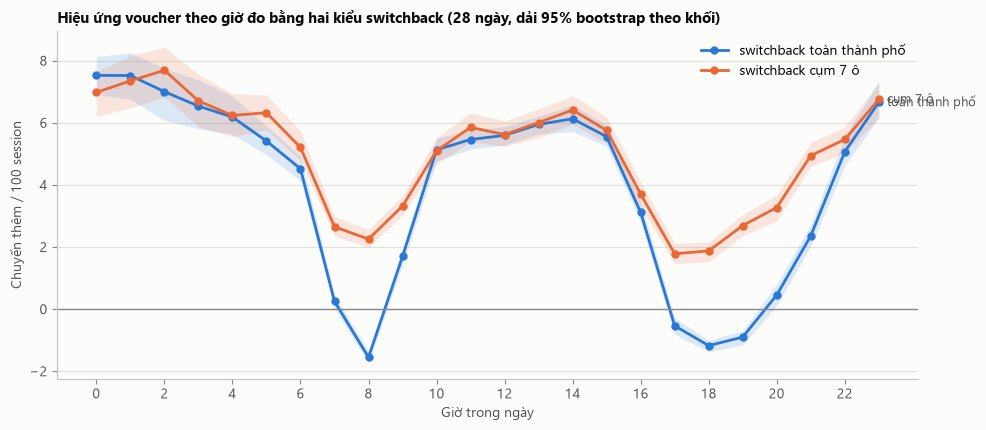

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.4))
for name, color in (("toàn thành phố", C1), ("cụm 7 ô", C2)):
    t = by_hour.loc[name]
    ax.fill_between(t["hour"], 100 * t["lo"], 100 * t["hi"], color=color, alpha=0.15, linewidth=0)
    ax.plot(t["hour"], 100 * t["tau"], color=color, linewidth=2, marker="o", markersize=5, label=f"switchback {name}")
    ax.annotate(name, xy=(23, 100 * t["tau"].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK_2, fontsize=9)
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_xlabel("Giờ trong ngày")
ax.set_ylabel("Chuyến thêm / 100 session")
ax.set_xticks(range(0, 24, 2))
ax.legend(frameon=False, loc="upper right")
ax.set_title("Hiệu ứng voucher theo giờ đo bằng hai kiểu switchback (28 ngày, dải 95% bootstrap theo khối)")
fig.tight_layout()
save_figure(fig, "04_switchback_theo_gio")

- **Switchback toàn thành phố** thấy đúng tác hại **8h và 17–19h** (cận trên khoảng tin cậy dưới 0), trùng hoàn toàn với phép so "mọi khách / không ai" — đây là bằng chứng cho luật tắt cố định theo giờ (`analysis.hour_rule`).
- **Switchback cụm 7 ô** cho hiệu ứng **dương** ở cùng giờ. Cụm đang bật voucher mượn xe của cụm đang tắt bên cạnh: thiết kế theo cụm không thấy được tác hại vì tác hại bị đẩy sang cụm khác (notebook 03: chệch +65% so với GTE).
- Trên W1 switchback toàn thành phố chỉ còn 18h có hại rõ (CI rộng hơn vì biến động theo ngày; `runs/s9/w1/summary.md`).


## 4. Ngưỡng theo độ căng trước khối (mới) so với ngưỡng theo giờ (cũ)

**Cách mới:** từ switchback toàn thành phố, gom các khối theo độ căng đo ở **slot cuối trước khối** (`system_pre` toàn thành phố, `ring_pre`, `cell_pre` theo session), ước lượng tác dụng lên tỷ lệ hoàn thành trong từng bin với bootstrap theo khối, rồi lấy zero crossing của đường isotonic làm θ̂_tension. **Cách cũ:** gán cho mỗi session τ(h) và cost(h) của giờ của nó rồi chọn θ cho tổng lợi ích lớn nhất — (A) không ngân sách, (B) có ngân sách B. Bảng đọc từ `runs/s9/w0` (`python -m analysis.tension_curve`).


In [13]:
curves = pd.read_parquet(S9 / "curve_by_tension.parquet")
thresholds = pd.read_parquet(S9 / "thresholds.parquet").set_index("moderator")
summary9 = json.loads((S9 / "summary.json").read_text(encoding="utf-8"))
hour_method = pd.DataFrame({m: {"θ̂ (A)": v["theta_hat_A"], "CI (A)": tuple(v["ci_A"]), "θ̂ (B)": v["theta_hat_B"], "CI (B)": tuple(v["ci_B"])}
                            for m, v in summary9["theta_hat_hour"].items()}).T
pd.concat({"theo độ căng": thresholds[["theta_hat", "ci_lo", "ci_hi", "share_boot_zero"]], "theo giờ": hour_method}, axis=1)


theo độ căng                                 theo giờ                                
              theta_hat ci_lo     ci_hi share_boot_zero   θ̂ (A)       CI (A) θ̂ (B)      CI (B)
system_pre     0.074143   0.0  0.219837           0.378      0.0  (0.0, 0.15)    1.6  (1.6, 1.6)
ring_pre       0.000000   0.0  0.318182           0.704      0.0   (0.0, 0.0)    2.3  (2.3, 2.3)
cell_pre       0.000000   0.0  0.136986           0.944      0.0   (0.0, 0.0)    2.4  (2.4, 2.4)

WindowsPath('C:/Work/VinAI/GSM/Supply-Aware-Promotion-Uplift/docs/figures/04_tac_dung_theo_do_cang.png')

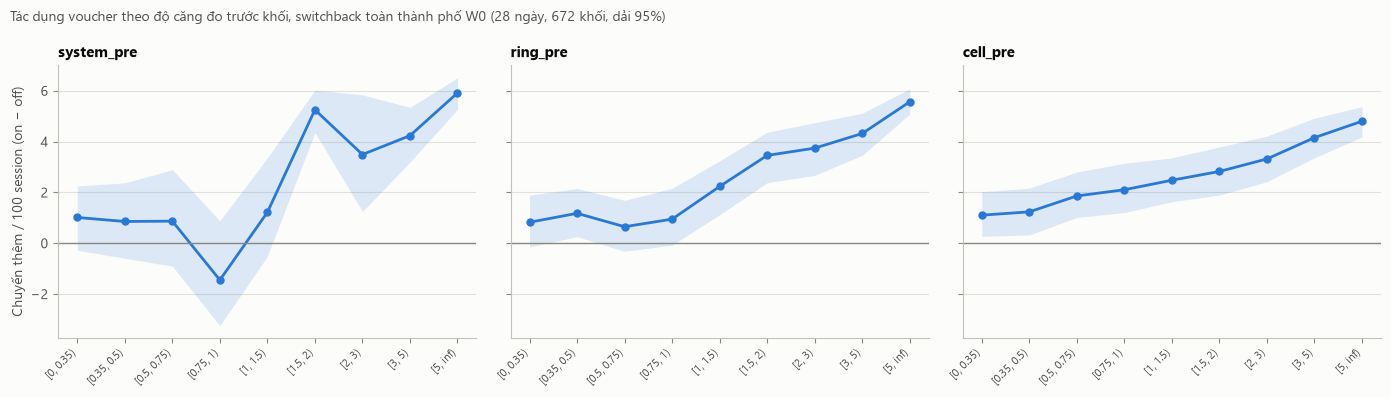

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, m in zip(axes, ("system_pre", "ring_pre", "cell_pre")):
    c = curves[curves["moderator"] == m].reset_index(drop=True)
    x = np.arange(len(c))
    ax.fill_between(x, 100 * c["ci_lo"], 100 * c["ci_hi"], color=C1, alpha=0.15, linewidth=0)
    ax.plot(x, 100 * c["effect"], color=C1, linewidth=2, marker="o", markersize=5)
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.set_xticks(x, [str(b) for b in c["bin"]], rotation=45, ha="right", fontsize=8)
    ax.set_title(m)
axes[0].set_ylabel("Chuyến thêm / 100 session (on − off)")
fig.suptitle("Tác dụng voucher theo độ căng đo trước khối, switchback toàn thành phố W0 (28 ngày, 672 khối, dải 95%)",
             x=0.01, ha="left", color=INK_2, fontsize=10)
fig.tight_layout()
save_figure(fig, "04_tac_dung_theo_do_cang")


WindowsPath('C:/Work/VinAI/GSM/Supply-Aware-Promotion-Uplift/docs/figures/04_duong_loi_ich_theta_hat.png')

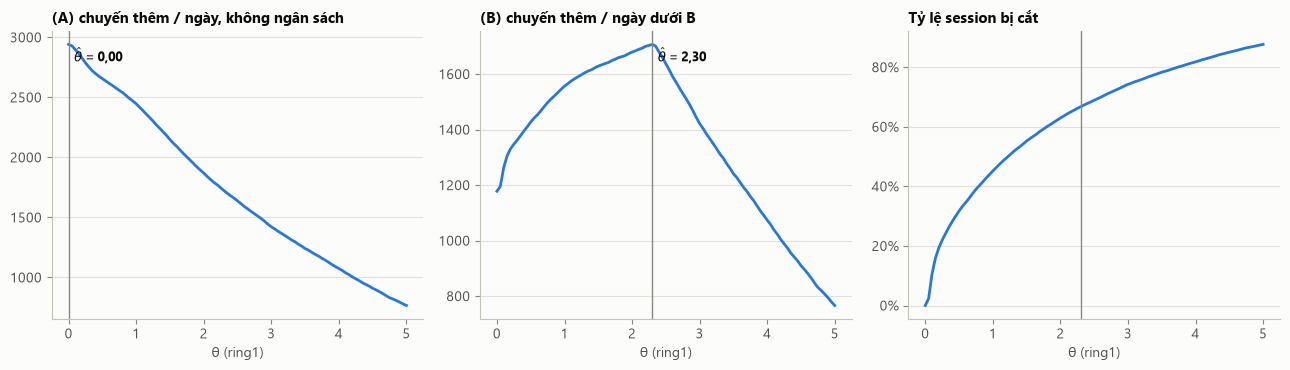

In [15]:
B_day = tension_curve.budget_per_day_of(BUDGET)
hm = tension_curve.hour_theta_hat(frame_all, "ring_pre", eff_all, n_days=28.0, budget_per_day=B_day)
THETA_A, THETA_B = hm["theta_hat_A"], hm["theta_hat_B"]
THETA_T = float(thresholds.loc["ring_pre", "theta_hat"])
cv = hm["curves"]
cv = cv[cv["theta"] <= 5.0]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col, title in ((axes[0], "gain_A", "(A) chuyến thêm / ngày, không ngân sách"),
                       (axes[1], "gain_B", "(B) chuyến thêm / ngày dưới B"),
                       (axes[2], "share_cut", "Tỷ lệ session bị cắt")):
    y = cv[col] * (100 if col == "share_cut" else 1)
    ax.plot(cv["theta"], y, color=C1, linewidth=2)
    best = THETA_A if col == "gain_A" else THETA_B
    ax.axvline(best, color=MUTED, linewidth=1)
    if col != "share_cut":
        ax.annotate(tex(f"θ̂ = {vn(best, 2)}"), xy=(best, float(y.max())), xytext=(4, -2), textcoords="offset points",
                    va="top", color=INK, fontsize=9, fontweight="bold")
    ax.set_title(title)
    ax.set_xlabel("θ (ring1)")
axes[2].yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
fig.tight_layout()
save_figure(fig, "04_duong_loi_ich_theta_hat")


- **Theo độ căng:** tác dụng tăng đơn điệu theo độ căng và **không âm ở bin nào** (toàn thành phố < 1,5: +0,9…+1,2 chuyến / 100 session, CI chứa 0; ≥ 1,5: +3,5…+5,9), nên θ̂_tension ≈ 0 (`ring1` 0,00 [0; 0,32]). Trên hai thế giới này độ căng trước khối dự báo **mức lợi** chứ không dự báo **tác hại**; tác hại là hiện tượng theo giờ cao điểm.
- **Theo giờ:** θ̂ (A) = 0 (không có giờ nào đáng cắt khi không có ngân sách), θ̂ (B) `ring1` = 2,3 — trùng chỗ đường tác dụng bật lên (1,5–2). Mục 5 chấm cả ba bằng regret trên quét θ.


## 5. θ̂ so với θ\*: regret theo số chuyến

θ\* không phải một số mà là **tập** các θ không kém θ tốt nhất (kiểm định ghép cặp theo seed, đã hiệu chỉnh so sánh bội). Một θ̂ được chấm bằng **regret**: N(θ tốt nhất) − N(θ̂) trên quét 16 mức θ × 30 seed với điểm `τ̂(x)/1.000đ` DR và phạm vi `ring1` (`runs/s10/w0/sweep_ring1_dr`). Để tránh "winner's curse", chọn θ trên nửa seed và đo regret trên nửa còn lại.


,theta,mean,se,share_cells_off,spent_mean,spent_over_B,in_set
0,0.00,21546.27,18.11,0.00,1.134464e+08,1.00,False
1,0.10,21549.33,16.85,0.01,1.133196e+08,1.00,False
2,0.20,21605.40,16.32,0.04,1.131624e+08,0.99,False
3,0.30,21650.87,15.53,0.07,1.133997e+08,1.00,False
4,0.40,21684.20,15.52,0.10,1.131703e+08,0.99,False
5,0.50,21705.93,17.96,0.13,1.121572e+08,0.99,False
6,0.60,21750.80,17.42,0.16,1.127497e+08,0.99,False
7,0.80,21774.23,16.31,0.21,1.126828e+08,0.99,False
8,1.00,21796.37,16.31,0.26,1.116684e+08,0.98,False
9,1.25,21820.47,15.69,0.31,1.124915e+08,0.99,True


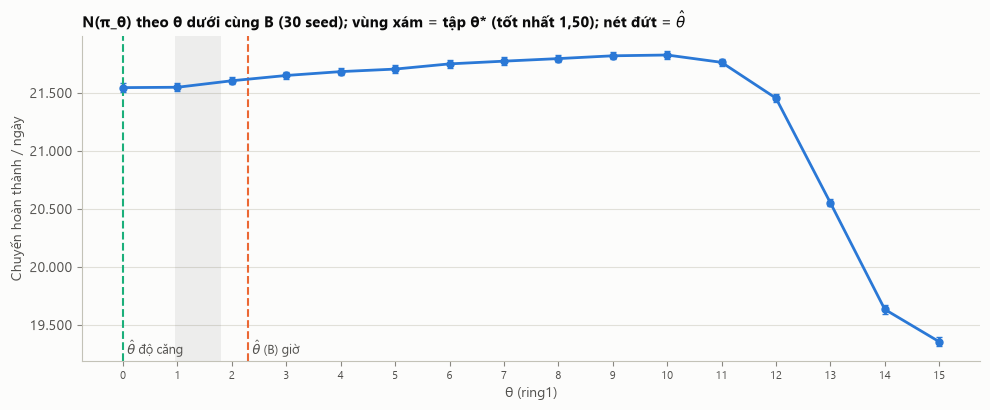

In [16]:
runs_sw = pd.read_parquet(SW_RING_DR / "results" / "policy_results.parquet")
by_theta = metrics.sweep_by_theta(runs_sw)
best, lo, hi = metrics.theta_star_interval(metrics.theta_star_set(runs_sw))
th = by_theta.index.to_numpy()
x = np.arange(len(th))
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.axvspan(np.interp(lo, th, x) - 0.3, np.interp(hi, th, x) + 0.3, color=INK, alpha=0.06, linewidth=0)
ax.errorbar(x, by_theta["mean"], yerr=1.96 * by_theta["se"], color=C1, linewidth=2, marker="o", markersize=5, capsize=2)
for t_hat, label, color in ((THETA_T, "θ̂ độ căng", C3), (THETA_B, "θ̂ (B) giờ", C2)):
    ax.axvline(np.interp(t_hat, th, x), color=color, linewidth=1.5, linestyle="--")
    ax.annotate(tex(label), xy=(np.interp(t_hat, th, x), 0.02), xycoords=("data", "axes fraction"), xytext=(3, 0),
                textcoords="offset points", color=INK_2, fontsize=9)
ax.set_xticks(x, [f"{v:g}" for v in th], fontsize=8)
ax.set_xlabel("θ (ring1)")
ax.set_ylabel("Chuyến hoàn thành / ngày")
ax.yaxis.set_major_formatter(lambda v, _: vn(v))
ax.set_title(tex(f"N(π_θ) theo θ dưới cùng B (30 seed); vùng xám = tập θ* (tốt nhất {vn(best, 2)}); nét đứt = θ̂"))
fig.tight_layout()
save_figure(fig, "04_n_theo_theta_ring1")
by_theta.round(2)


In [17]:
rows = []
for label, t_hat in (("θ = 0 (không cắt ô)", 0.0), ("θ̂ độ căng (ring1)", THETA_T), ("θ̂ (B) theo giờ (ring1)", THETA_B), ("θ̂ (B) theo giờ (city)", 1.6)):
    r = metrics.sweep_regret(runs_sw, t_hat)
    g = evaluation.gain_recovered(runs_sw, t_hat)
    rows.append({"ngưỡng": label, "θ": t_hat, "θ tốt nhất": r["theta_best"], "regret": r["regret"], "SE": r["se"],
                 "CI thấp": r["lo"], "CI cao": r["hi"], "% của N tốt nhất": 100 * r["relative"],
                 "% lợi ích tối đa lấy lại": 100 * g["gain_recovered"]})
regret = pd.DataFrame(rows)
split = evaluation.split_seed_regret(runs_sw)
print("Chọn θ trên nửa seed, đo trên nửa kia:")
print(split[["chosen_on", "tested_on", "theta_chosen", "theta_best_heldout", "regret", "regret_se", "gain_recovered"]].round(3).to_string(index=False))
regret.round(2)


Chọn θ trên nửa seed, đo trên nửa kia:
chosen_on tested_on  theta_chosen  theta_best_heldout  regret  regret_se  gain_recovered
        A         B          1.50                1.25   0.000     12.485            1.00
        B         A          1.25                1.50  13.667     12.007            0.95


,ngưỡng,θ,θ tốt nhất,regret,SE,CI thấp,CI cao,% của N tốt nhất,% lợi ích tối đa lấy lại
0,θ = 0 (không cắt ô),0.0,1.5,281.03,10.63,259.29,302.78,1.29,0.00
1,θ̂ độ căng (ring1),0.0,1.5,281.03,10.63,259.29,302.78,1.29,0.00
2,θ̂ (B) theo giờ (ring1),2.3,1.5,155.91,7.43,140.71,171.11,0.71,44.52
3,θ̂ (B) theo giờ (city),1.6,1.5,12.66,1.61,9.37,15.95,0.06,95.50


WindowsPath('C:/Work/VinAI/GSM/Supply-Aware-Promotion-Uplift/docs/figures/04_regret_theta_hat.png')

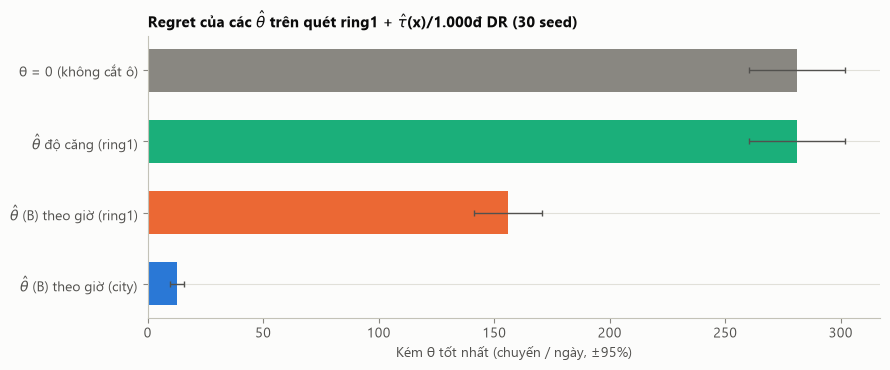

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(regret))
ax.barh(y, regret["regret"], xerr=1.96 * regret["SE"], color=[MUTED, C3, C2, C1], height=0.6,
        error_kw={"ecolor": INK_2, "elinewidth": 1, "capsize": 2})
ax.set_yticks(y, [tex(n) for n in regret["ngưỡng"]])
ax.invert_yaxis()
ax.set_xlabel("Kém θ tốt nhất (chuyến / ngày, ±95%)")
ax.set_title(tex("Regret của các θ̂ trên quét ring1 + τ̂(x)/1.000đ DR (30 seed)"))
fig.tight_layout()
save_figure(fig, "04_regret_theta_hat")


- N(π_θ) tăng từ θ = 0 tới đỉnh ở **θ = 1,5** (+281 chuyến/ngày, +1,3%; tập θ\* {1,25; 1,5}) rồi giảm; θ = 5 chỉ chi 57% B. Chọn θ trên nửa seed rồi đo trên nửa kia: regret ≈ 0 (lấy lại 95–100% lợi ích tối đa) — đường đủ phẳng quanh đỉnh để chọn được từ dữ liệu.
- **θ̂ độ căng = 0** không lấy lại gì (regret +281): đúng với mục 4, trên thế giới này độ căng gộp theo bin không có vùng âm.
- **θ̂ (B) theo giờ = 2,3** cắt hơi quá (regret 156 ± 7, lấy lại 44%); 1,6 (θ̂_B của `city`) gần tối ưu trên `ring1` (regret 13). Trên W1 đỉnh ở θ = 1,25 (+311) và θ̂ (B) = 2,15 lấy lại 62% (`runs/s10/w1/eval`).


In [19]:
distribution = pd.read_parquet(S9 / "tension_distribution.parquet").set_index("label")
distribution[["n_slots", "share_below_cut", "q10", "q25", "median", "q75", "q90"]].round(3)


,n_slots,share_below_cut,q10,q25,median,q75,q90
label,,,,,,,
all_off,480,0.004,0.671,1.413,3.645,5.216,11.377
all_on,480,0.321,0.084,0.189,1.200,2.041,6.229
legacy,2688,0.042,0.471,0.947,2.597,3.957,9.726


Giả thuyết "chưa kiểm" trên thế giới cũ nay kiểm được: độ căng toàn thành phố đo khi **không phát voucher** có trung vị 3,65 và chỉ 0,4% slot căng (< 0,35); khi **phát cho mọi người** trung vị còn 1,20 và 32% slot căng; dưới luật cũ 2,60 và 4,2%. Voucher làm thêm xe đi đón nên độ căng giảm ~3 lần. Ngưỡng học trên độ căng không voucher rồi áp lên độ căng dưới chính sách sẽ cắt quá tay — cơ chế khiến (B) cắt nhiều trên thế giới cũ và khiến ngưỡng học cho B = 0,3 không chuyển sang B lớn (notebook 02, độ vững). Ngưỡng vận hành phải đọc trên độ căng đo **dưới chính sách**.


## 6. Kết luận và chính sách khuyến nghị

In [20]:
FINAL = {"all_off": "không phát voucher", "all_on_B": "phát cho mọi khách đến khi hết B", "random": "ngẫu nhiên, θ = 0",
         "tau_x_dr_all_kvnd": "τ̂(x)/1.000đ DR, θ = 0", "pi_tension_ring1_dr_kvnd": "τ̂(x)/1.000đ DR + ring1, θ̂ độ căng",
         "pi_hourB_ring1_dr_kvnd": "τ̂(x)/1.000đ DR + ring1, θ̂ (B)", "pi_hourB_city_dr_kvnd": "τ̂(x)/1.000đ DR + city, θ̂ (B)",
         "hour_off_dr_kvnd": "τ̂(x)/1.000đ DR + tắt giờ có hại", "oracle": "oracle"}
final = summarize(policy_runs_df, reference="all_on_B", order=list(FINAL)).set_index("label")
final.assign(**{"chính sách": pd.Series(FINAL)})[["chính sách", "theta", "N_mean", "N_se", "dN_vs_ref", "dN_vs_ref_se",
                                                  "spent_mean", "share_cells_off"]].round(3)


,chính sách,theta,N_mean,N_se,dN_vs_ref,dN_vs_ref_se,spent_mean,share_cells_off
label,,,,,,,,
all_off,không phát voucher,NaN,19357.433,20.535,-998.500,10.834,0.000000e+00,1.000
all_on_B,phát cho mọi khách đến khi hết B,NaN,20355.933,18.934,0.000,0.000,1.137563e+08,0.000
random,"ngẫu nhiên, θ = 0",0.0,20763.200,16.893,407.267,12.784,1.137441e+08,0.000
tau_x_dr_all_kvnd,"τ̂(x)/1.000đ DR, θ = 0",0.0,21546.267,18.114,1190.333,12.376,1.134464e+08,0.000
pi_tension_ring1_dr_kvnd,"τ̂(x)/1.000đ DR + ring1, θ̂ độ căng",0.0,21546.267,18.114,1190.333,12.376,1.134464e+08,0.000
pi_hourB_ring1_dr_kvnd,"τ̂(x)/1.000đ DR + ring1, θ̂ (B)",2.3,21706.800,15.370,1350.867,14.512,1.113781e+08,0.512
pi_hourB_city_dr_kvnd,"τ̂(x)/1.000đ DR + city, θ̂ (B)",1.6,21825.333,17.206,1469.400,13.130,1.116703e+08,0.353
hour_off_dr_kvnd,τ̂(x)/1.000đ DR + tắt giờ có hại,0.0,21802.900,14.118,1446.967,13.616,1.137196e+08,0.000
oracle,oracle,0.0,21634.633,15.517,1278.700,13.863,1.136966e+08,0.000


1. **Hàm điểm:** xếp rider theo **chuyến thêm mỗi 1.000đ**, không theo chuyến thêm mỗi lượt phát. Điểm theo lượt phát không hơn phát ngẫu nhiên dưới cùng ngân sách.
2. **Tầng vùng:** trên W0 thông tin căng cung thêm +160 (`ring1`, θ̂_B 2,3) đến +279 (`city`, 1,6) chuyến/ngày so với tầng rider; luật tắt cố định ở giờ có hại (8h, 17–19h) đạt gần như cùng mức (+257), nên trên W0 **độ căng ngang luật giờ** (+22 ± 11, H1). Trên W1 tầng vùng hơn luật giờ **+142 ± 16** (H2): khi căng không theo giờ, chỉ luật theo độ căng mới bắt được.
3. **Ngưỡng:** độ căng trước khối dự báo mức lợi chứ không dự báo tác hại (θ̂_tension = 0); ngưỡng dùng được là θ̂ (B) có ngân sách (2,3 / 1,6) hoặc θ tốt nhất của quét (1,5); quét θ chọn trên nửa seed lấy lại 95–100% lợi ích tối đa. Ngưỡng phụ thuộc B và phải đọc trên độ căng đo dưới chính sách (mục 5, notebook 02).
4. **Chính sách khuyến nghị (W0, B = 0,3 × chi all_on):** `τ̂(x)/1.000đ` DR + tầng `city` θ̂_B = 1,6, +1.469 ± 13 chuyến/ngày so với phát cho mọi người (lấp 115% khoảng cách tới oracle); trên W1: + `ring1` θ̂_B = 2,15, +1.249 ± 29.
